In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA = Path("../data")
files = ["eq_returns.csv", "eq_indicator.csv", "eq_stock_metadata.csv",
         "psych_bullish.csv", "psych_bearish.csv", "psych_stock_metadata.csv"]

for f in files:
	df = pd.read_csv(DATA / f, nrows=5)
	print(f"=== {f} ===")
	print("columns (first 8):", list(df.columns[:8]))
	print("n columns:", len(df.columns))
	print(df.iloc[:5, :6])
	print()

ret = pd.read_csv(DATA / "eq_returns.csv")
print("returns shape:", ret.shape)
print("first col values:", ret.iloc[:3, 0].tolist(), "...", ret.iloc[-3:, 0].tolist())
print("fraction NaN:", ret.isna().mean().mean())
vals = ret.iloc[:, 1:].stack()
print(vals.describe())

=== eq_returns.csv ===
columns (first 8): ['date', '10006', '10057', '10078', '10104', '10107', '10108', '10137']
n columns: 1336
         date     10006     10057  10078  10104  10107
0  1980-01-02  0.007299 -0.004785    NaN    NaN    NaN
1  1980-01-03 -0.014493  0.009615    NaN    NaN    NaN
2  1980-01-04  0.014706  0.028571    NaN    NaN    NaN
3  1980-01-07  0.036232  0.000000    NaN    NaN    NaN
4  1980-01-08  0.006993  0.000000    NaN    NaN    NaN

=== eq_indicator.csv ===
columns (first 8): ['date', '10006', '10057', '10078', '10104', '10107', '10108', '10137']
n columns: 1336
         date  10006  10057  10078  10104  10107
0  1980-01-02      1      1      0      0      0
1  1980-01-03      1      1      0      0      0
2  1980-01-04      1      1      0      0      0
3  1980-01-07      1      1      0      0      0
4  1980-01-08      1      1      0      0      0

=== eq_stock_metadata.csv ===
columns (first 8): ['permno', 'cname', 'gics']
n columns: 3
   permno             

In [3]:
ret = pd.read_csv(DATA / "eq_returns.csv", index_col="date", parse_dates=True)
ind = pd.read_csv(DATA / "eq_indicator.csv", index_col="date", parse_dates=True)
meta = pd.read_csv(DATA / "eq_stock_metadata.csv")

# Duplicate permnos: pandas renamed the 2nd copy 'XXXX.1' -> make it 'XXXX_b'
fix = lambda cols: [c[:-2] + "_b" if c.endswith(".1") else c for c in cols]
ret.columns, ind.columns = fix(ret.columns), fix(ind.columns)

# Give metadata the same IDs (2nd occurrence of a permno -> '_b')
meta["id"] = meta.permno.astype(str)
meta.loc[meta.permno.duplicated(), "id"] += "_b"
meta = meta.set_index("id")

# Sanity: metadata rows in the same order as the columns?
print("meta order matches columns:", list(meta.index) == list(ret.columns))
print("indicator columns match returns:", ind.columns.equals(ret.columns),
      "| dates match:", ind.index.equals(ret.index))

# Drop securities with no data at all
empty = ret.columns[ret.notna().sum() == 0]
print("dropping empty:", list(empty))
ret, ind, meta = ret.drop(columns=empty), ind.drop(columns=empty), meta.drop(index=empty)

# How related are the duplicate pairs? (for the report)
for b in [c for c in ret.columns if c.endswith("_b")]:
    a = b[:-2]
    print(f"{a}: corr on overlap = {ret[a].corr(ret[b]):.2f}")

# --- rest of Step 2 ---
print("\nmembers per day:\n", ind.sum(axis=1).describe())
print("\nnon-NaN returns per day:\n", ret.notna().sum(axis=1).describe())
print("\nnon-member cells WITH a return:", (ret.notna() & (ind == 0)).sum().sum())
print("member cells with NaN return:  ", (ret.isna() & (ind == 1)).sum().sum())
n = ret.notna().sum().sum()
print("\nfraction exact zeros:", (ret == 0).sum().sum() / n)
print("cells with |r| > 0.5:", (ret.abs() > 0.5).sum().sum())

meta order matches columns: True
indicator columns match returns: True | dates match: True
dropping empty: ['91611', '91650', '91883', '91926', '91937', '92121', '92156', '92156_b', '92157', '92157_b', '92293', '92602', '92611', '92618', '92655', '92709', '92890', '92988', '93096', '93159', '93422']
12431: corr on overlap = 0.10
12650: corr on overlap = 0.15
19166: corr on overlap = 0.12
21979: corr on overlap = 0.14
23536: corr on overlap = 0.28
25232: corr on overlap = 0.06
25582: corr on overlap = 0.13
26382: corr on overlap = 0.23
32707: corr on overlap = 0.13
33312: corr on overlap = 0.39
39087: corr on overlap = 0.30
45356: corr on overlap = 0.17
46703: corr on overlap = 0.20
48653: corr on overlap = 0.06
77157: corr on overlap = 0.19
79057: corr on overlap = 0.15
79129: corr on overlap = 0.14
79237: corr on overlap = 0.18
90537: corr on overlap = 0.47

members per day:
 count    8577.000000
mean      499.793751
std         0.771168
min       489.000000
25%       500.000000
50%  

count    4.227347e+06
mean     3.465494e-02
std      1.057436e+00
min     -3.156312e+01
25%     -5.550066e-01
50%      0.000000e+00
75%      6.021651e-01
max      5.639968e+01
dtype: float64
excess kurtosis: 22.74963679238499
fraction |v| > 3: 0.00493
fraction |v| > 5: 0.00076
fraction |v| > 10: 0.00008


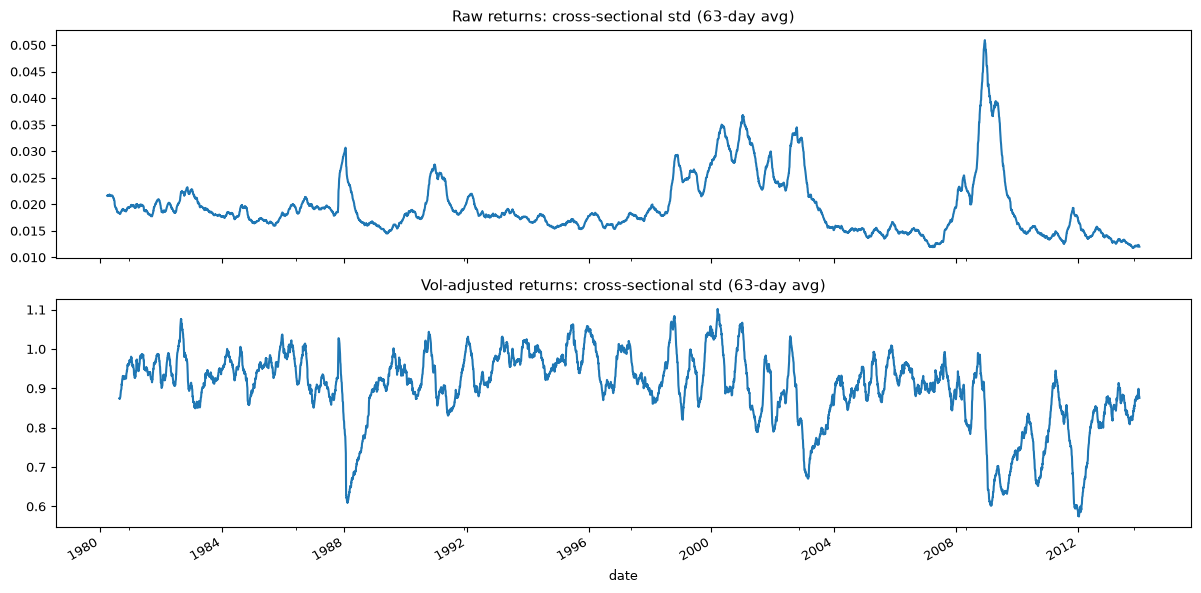

In [4]:
import matplotlib.pyplot as plt

def ewma_vol(R, beta1=0.97, beta2=0.99, var0=0.02**2, burn_in=100):
    """R: (T, N) raw returns with NaN. Returns sigma_hat (T, N): estimate at the END of day t."""
    T, N = R.shape
    mu = np.zeros(N)
    var = np.full(N, var0)
    seen = np.zeros(N, dtype=int)
    sig = np.full((T, N), np.nan)
    for t in range(T):
        r = R[t]
        obs = ~np.isnan(r)
        mu[obs] = (1 - beta2) * r[obs] + beta2 * mu[obs]          # eq (3)
        a = r[obs] - mu[obs]
        var[obs] = (1 - beta1) * a**2 + beta1 * var[obs]          # eq (2)
        seen[obs] += 1
        ok = seen >= burn_in                                      # carry estimate forward over gaps
        sig[t, ok] = np.sqrt(var[ok])
    return sig

sig = pd.DataFrame(ewma_vol(ret.values), index=ret.index, columns=ret.columns)
vadj = ret / sig.shift(1)            # r_t / sigma_{t-1}  <- the critical shift

# Sanity checks on member cells only
m = ind.astype(bool)
v = vadj.where(m).stack()
print(v.describe())
print("excess kurtosis:", v.kurt())
for k in [3, 5, 10]:
    print(f"fraction |v| > {k}: {(v.abs() > k).mean():.5f}")

# Figure for the report: does vol adjustment make the series more stationary?
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ret.where(m).std(axis=1).rolling(63).mean().plot(ax=ax[0])
ax[0].set_title("Raw returns: cross-sectional std (63-day avg)")
vadj.where(m).std(axis=1).rolling(63).mean().plot(ax=ax[1])
ax[1].set_title("Vol-adjusted returns: cross-sectional std (63-day avg)")
plt.tight_layout(); plt.show()

In [5]:
vadj_c = vadj.clip(-5, 5)      # features / training targets only
Y = vadj.shift(-1)             # Y[t] = realized vol-adj return on day t+1 (UNclipped)
mem = ind.astype(bool)

def sharpe(x):
    return x.mean() / x.std() * np.sqrt(252)

def evaluate(P, start="2011-01-01", end="2013-12-31", windows=None,
             demean=False, label="", plot=True):
    P = P.where(mem).loc[start:end]          # only members on day t
    Yw = Y.loc[start:end]
    if demean:                               # market-neutral: zero mean prediction each day
        P = P.sub(P.mean(axis=1), axis=0)
    valid = P.notna() & Yw.notna()
    P, Yw = P.where(valid), Yw.where(valid)

    # P&L, eq (6)
    pnl = (P * Yw).sum(axis=1, min_count=1).dropna()

    # Daily Spearman (rank IC)
    rp, ry = P.rank(axis=1), Yw.rank(axis=1)
    rp, ry = rp.sub(rp.mean(axis=1), axis=0), ry.sub(ry.mean(axis=1), axis=0)
    ic = ((rp * ry).sum(axis=1) /
          np.sqrt((rp**2).sum(axis=1) * (ry**2).sum(axis=1))).dropna()

    # Holding period, eq (7), stocks with >= 20 predictions
    counts = P.notna().sum()
    Pk = P.loc[:, counts >= 20]
    hp = (Pk.abs().iloc[1:].mean() / Pk.diff().abs().iloc[1:].mean())
    hp = hp.replace(np.inf, np.nan).dropna()

    # Correlation with equal-weight long-only portfolio of members
    mkt = Y.where(mem).loc[start:end].mean(axis=1).reindex(pnl.index)

    out = {
        "Sharpe": sharpe(pnl),
        "mean IC": ic.mean(),
        "IC t-stat": ic.mean() / ic.std() * np.sqrt(len(ic)),
        "holding period (days)": hp.mean(),
        "corr w/ market": pnl.corr(mkt),
        "min preds/day": int(valid.sum(axis=1).loc[pnl.index].min()),
    }
    print(f"===== {label} [{start} -> {end}] =====")
    for k, v in out.items():
        print(f"{k:>22}: {v:.3f}" if isinstance(v, float) else f"{k:>22}: {v}")
    print("Sharpe by year:", pnl.groupby(pnl.index.year).apply(sharpe).round(2).to_dict())
    if windows:
        for a, b in windows:
            print(f"Sharpe {a}-{b}: {sharpe(pnl.loc[a:b]):.2f}")

    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
        pnl.cumsum().plot(ax=ax[0], title=f"{label}: cumulative P&L")
        ic.cumsum().plot(ax=ax[1], title=f"{label}: cumulative rank IC")
        plt.tight_layout(); plt.show()
    return pnl, ic, out

/var/folders/3y/b7yfwh1s3rg_mvq_621h51m80000gn/T/ipykernel_49880/3872727013.py:38: RuntimeWarning: divide by zero encountered in scalar divide
  "IC t-stat": ic.mean() / ic.std() * np.sqrt(len(ic)),


===== CHEAT (should be absurd) [2011-01-01 -> 2013-12-31] =====
                Sharpe: 16.598
               mean IC: 1.000
             IC t-stat: inf
 holding period (days): 0.684
        corr w/ market: -0.188
         min preds/day: 496
Sharpe by year: {2011: 13.05, 2012: 22.18, 2013: 23.74}
===== random (should be ~0) [2011-01-01 -> 2013-12-31] =====
                Sharpe: 0.314
               mean IC: 0.002
             IC t-stat: 1.296
 holding period (days): 0.708
        corr w/ market: 0.056
         min preds/day: 496
Sharpe by year: {2011: 0.09, 2012: -0.26, 2013: 1.16}


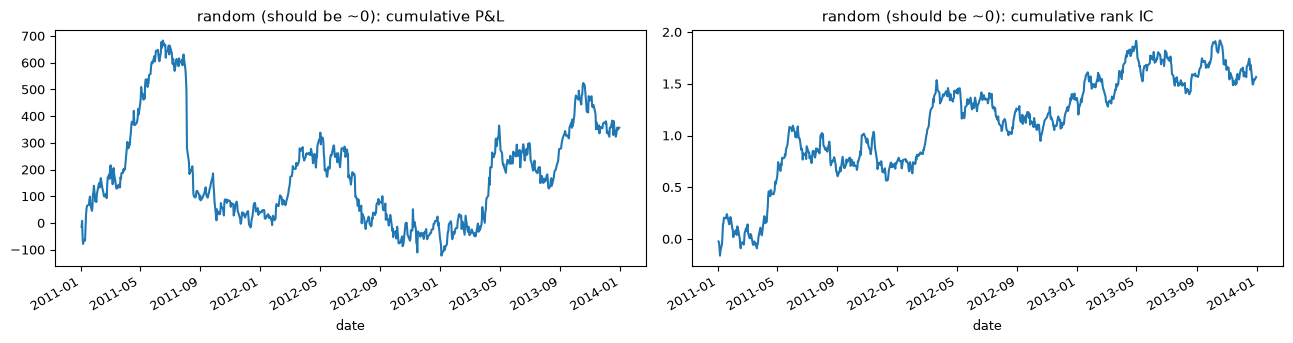

===== long-only (high market corr) [2011-01-01 -> 2013-12-31] =====
                Sharpe: 1.101
               mean IC: nan
             IC t-stat: nan
 holding period (days): nan
        corr w/ market: 1.000
         min preds/day: 496
Sharpe by year: {2011: 0.06, 2012: 1.22, 2013: 2.47}
===== 5-day reversal, full history [1985-01-01 -> 2013-12-31] =====
                Sharpe: 2.199
               mean IC: 0.024
             IC t-stat: 18.025
 holding period (days): 1.577
        corr w/ market: 0.156
         min preds/day: 493
Sharpe by year: {1985: 1.14, 1986: 2.16, 1987: 4.42, 1988: 9.44, 1989: 2.49, 1990: 0.58, 1991: 6.12, 1992: 6.29, 1993: 2.85, 1994: 6.22, 1995: 3.47, 1996: 4.8, 1997: 3.49, 1998: 0.88, 1999: 1.95, 2000: 2.28, 2001: 0.91, 2002: 0.85, 2003: 1.47, 2004: 1.92, 2005: 1.8, 2006: 1.67, 2007: 1.05, 2008: 1.23, 2009: 1.45, 2010: 1.21, 2011: 1.55, 2012: -0.32, 2013: 0.85}
Sharpe 1985-1989: 3.25
Sharpe 1990-1994: 4.09
Sharpe 1995-1999: 2.59
Sharpe 2000-2004: 1.39
Shar

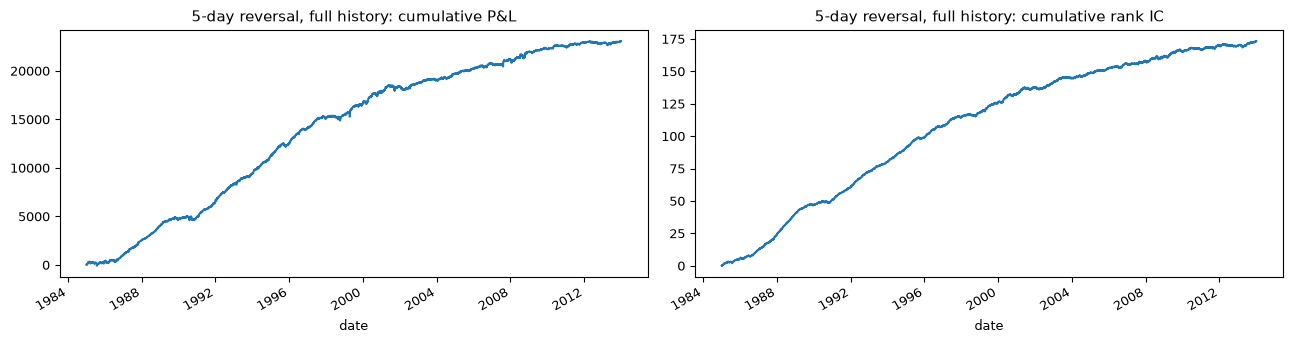

(date
 1985-01-02    18.112596
 1985-01-03    -1.769184
 1985-01-04    -2.198024
 1985-01-07     6.982897
 1985-01-08    14.215466
                 ...    
 2013-12-23    11.627417
 2013-12-24   -11.276762
 2013-12-26    -5.857038
 2013-12-27     1.157894
 2013-12-30    -0.170659
 Length: 7311, dtype: float64,
 date
 1985-01-02    0.114875
 1985-01-03    0.031005
 1985-01-04    0.019964
 1985-01-07    0.056026
 1985-01-08    0.102127
                 ...   
 2013-12-23    0.110097
 2013-12-24   -0.181032
 2013-12-26   -0.031558
 2013-12-27    0.041077
 2013-12-30   -0.017779
 Length: 7311, dtype: float64,
 {'Sharpe': np.float64(2.1993467654605876),
  'mean IC': np.float64(0.023704106828144004),
  'IC t-stat': np.float64(18.024685958435363),
  'holding period (days)': np.float64(1.5772340195466035),
  'corr w/ market': np.float64(0.15571083035276712),
  'min preds/day': 493})

In [6]:
rng = np.random.default_rng(42)
idx, cols = vadj.index, vadj.columns

P_cheat = Y.copy()                                                     # perfect foresight
P_rand  = pd.DataFrame(rng.standard_normal(vadj.shape), idx, cols)     # pure noise
P_long  = pd.DataFrame(1.0, idx, cols)                                 # always long
P_rev   = -vadj_c.rolling(5, min_periods=3).mean()                     # 5-day reversal

windows = [("1985", "1989"), ("1990", "1994"), ("1995", "1999"),
           ("2000", "2004"), ("2005", "2009"), ("2010", "2013")]

evaluate(P_cheat, label="CHEAT (should be absurd)", plot=False)
evaluate(P_rand,  label="random (should be ~0)")
evaluate(P_long,  label="long-only (high market corr)", plot=False)
evaluate(P_rev,   start="1985-01-01", label="5-day reversal, full history",
         windows=windows, demean=True)